In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files


# SleepSense – Sleep and Lifestyle Pattern Predictor

## 1. Introduction

SleepSense is a Machine Learning project that explores the relationship between sleep quality and lifestyle factors.

The project uses the Sleep Health and Lifestyle Dataset to analyse factors such as sleep duration, stress level, physical activity, age, BMI category, heart rate and daily steps.

The primary objective is to develop a supervised Machine Learning regression model that predicts an individual's Quality of Sleep score based on their lifestyle and health-related features.

## 2. Project Objectives

* Understand and explore the sleep health dataset.
* Perform data cleaning and preprocessing.
* Identify relationships between lifestyle factors and sleep quality through Exploratory Data Analysis (EDA).
* Train and compare suitable regression models.
* Evaluate model performance using appropriate regression metrics.
* Interpret the results and identify the limitations of the model.

## 3. Problem Statement

Sleep quality is associated with several lifestyle and health-related factors. This project investigates these relationships and develops a regression model to estimate sleep quality using the available dataset.

**Note:** SleepSense is an educational Machine Learning project. Its predictions are not medical diagnoses or clinically validated assessments.


In [11]:
from google.colab import files

uploaded = files.upload()

Saving Sleep_health_and_lifestyle_dataset.csv to Sleep_health_and_lifestyle_dataset (2).csv


In [12]:
df = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 4. Dataset Description

The project uses the Sleep Health and Lifestyle Dataset, which contains information about 374 individuals across 13 columns.

The dataset includes demographic details, lifestyle habits, sleep-related measurements and sleep disorder information.

Some important features include:

* **Age and Gender:** Basic demographic information.
* **Occupation:** Professional background.
* **Sleep Duration:** Average hours of sleep.
* **Quality of Sleep:** Target variable, scored from 1 to 10.
* **Physical Activity Level:** Daily physical activity.
* **Stress Level:** Reported stress score.
* **BMI Category:** Body Mass Index category.
* **Heart Rate and Blood Pressure:** Health-related measurements.
* **Daily Steps:** Number of steps taken per day.
* **Sleep Disorder:** Sleep disorder information, where available.

The target variable for this project is **Quality of Sleep**. The remaining selected features are used to predict this score.


## 5. Initial Dataset Inspection

After loading the dataset, we perform an initial inspection to understand its structure and contents.

The following commands are used:

* `df.head()` – Displays the first five rows of the dataset.
* `df.shape` – Shows the number of rows and columns.
* `df.info()` – Provides information about column names, data types and non-null values.

These checks help us understand the dataset before performing data cleaning and preprocessing.


In [13]:
df.head


<bound method NDFrame.head of      Person ID  Gender  Age            Occupation  Sleep Duration  \
0            1    Male   27     Software Engineer             6.1   
1            2    Male   28                Doctor             6.2   
2            3    Male   28                Doctor             6.2   
3            4    Male   28  Sales Representative             5.9   
4            5    Male   28  Sales Representative             5.9   
..         ...     ...  ...                   ...             ...   
369        370  Female   59                 Nurse             8.1   
370        371  Female   59                 Nurse             8.0   
371        372  Female   59                 Nurse             8.1   
372        373  Female   59                 Nurse             8.1   
373        374  Female   59                 Nurse             8.1   

     Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
0                   6                       42             6   Overweight   
1                   6                       60             8       Normal   
2                   6                       60             8       Normal   
3                   4                       30             8        Obese   
4                   4                       30             8        Obese   
..                ...                      ...           ...          ...   
369                 9                       75             3   Overweight   
370                 9                       75             3   Overweight   
371                 9                       75             3   Overweight   
372                 9                       75             3   Overweight   
373                 9                       75             3   Overweight   

    Blood Pressure  Heart Rate  Daily Steps Sleep Disorder  
0           126/83          77         4200            NaN  
1           125/80          75        10000            NaN  
2           125/80          75        10000            NaN  
3           140/90          85         3000    Sleep Apnea  
4           140/90          85         3000    Sleep Apnea  
..             ...         ...          ...            ...  
369         140/95          68         7000    Sleep Apnea  
370         140/95          68         7000    Sleep Apnea  
371         140/95          68         7000    Sleep Apnea  
372         140/95          68         7000    Sleep Apnea  
373         140/95          68         7000    Sleep Apnea  

[374 rows x 13 columns]>

In [14]:
df.shape

(374, 13)

In [15]:
df.columns.tolist()

['Person ID',
 'Gender',
 'Age',
 'Occupation',
 'Sleep Duration',
 'Quality of Sleep',
 'Physical Activity Level',
 'Stress Level',
 'BMI Category',
 'Blood Pressure',
 'Heart Rate',
 'Daily Steps',
 'Sleep Disorder']

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


## 6. Dataset Statistics and Missing Value Analysis

After the initial inspection, we analyse the dataset to understand its statistical properties and identify missing values.

Two important commands are used:

* `df.describe()` – Generates descriptive statistics for numerical columns, including mean, standard deviation, minimum, maximum and quartiles.
* `df.isnull().sum()` – Counts the missing values in each column.

### Observations

* The dataset contains 374 records and 13 columns.
* Most columns have complete data.
* The `Sleep Disorder` column contains 219 missing values.
* These missing values are considered during the preprocessing stage.


In [17]:
df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


In [18]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [19]:
print("Gender:")
print(df["Gender"].value_counts())

print("\nOccupation:")
print(df["Occupation"].value_counts())

print("\nBMI Category:")
print(df["BMI Category"].value_counts())

print("\nSleep Disorder:")
print(df["Sleep Disorder"].value_counts())

Gender:
Gender
Male      189
Female    185
Name: count, dtype: int64

Occupation:
Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1
Name: count, dtype: int64

BMI Category:
BMI Category
Normal           195
Overweight       148
Normal Weight     21
Obese             10
Name: count, dtype: int64

Sleep Disorder:
Sleep Disorder
Sleep Apnea    78
Insomnia       77
Name: count, dtype: int64


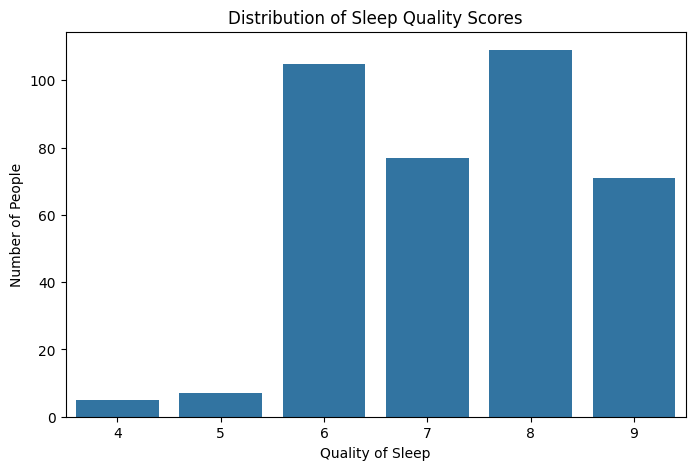

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Quality of Sleep")

plt.title("Distribution of Sleep Quality Scores")
plt.xlabel("Quality of Sleep")
plt.ylabel("Number of People")

plt.show()

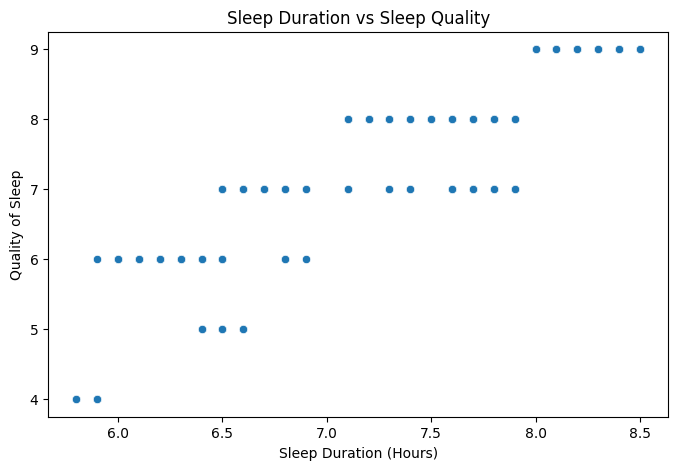

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Sleep Duration",
    y="Quality of Sleep"
)

plt.title("Sleep Duration vs Sleep Quality")
plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Quality of Sleep")

plt.show()

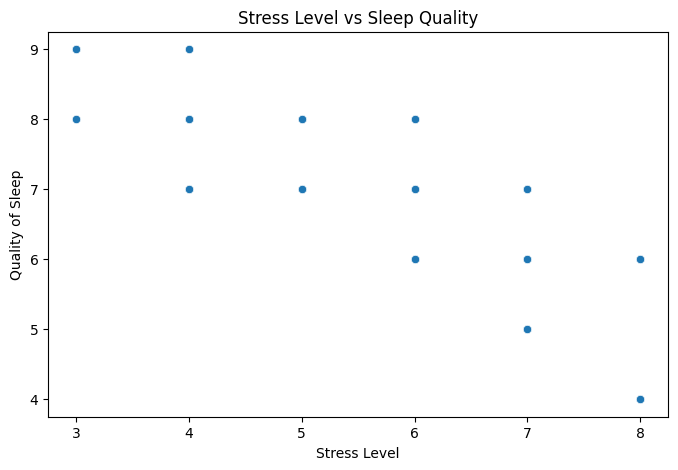

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Stress Level",
    y="Quality of Sleep"
)

plt.title("Stress Level vs Sleep Quality")
plt.xlabel("Stress Level")
plt.ylabel("Quality of Sleep")

plt.show()

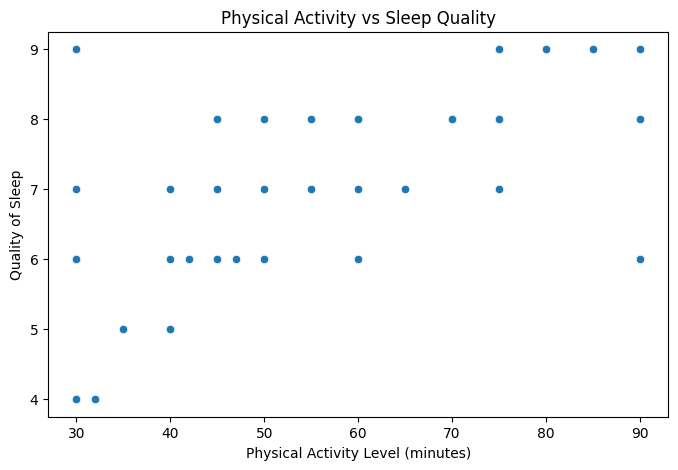

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Physical Activity Level",
    y="Quality of Sleep"
)

plt.title("Physical Activity vs Sleep Quality")
plt.xlabel("Physical Activity Level (minutes)")
plt.ylabel("Quality of Sleep")
plt.show()

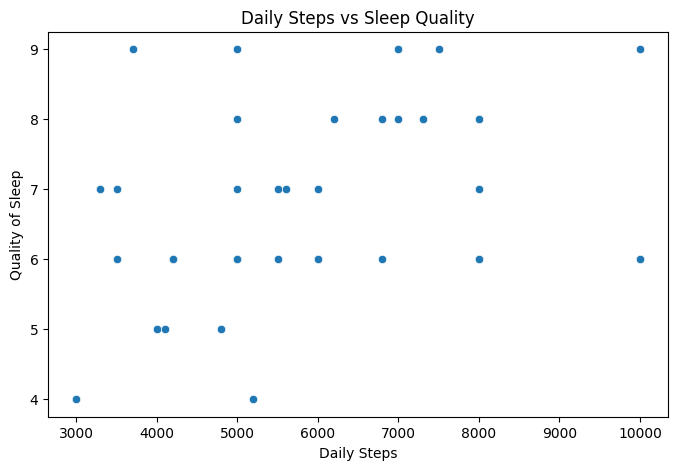

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Daily Steps",
    y="Quality of Sleep"
)

plt.title("Daily Steps vs Sleep Quality")
plt.xlabel("Daily Steps")
plt.ylabel("Quality of Sleep")
plt.show()

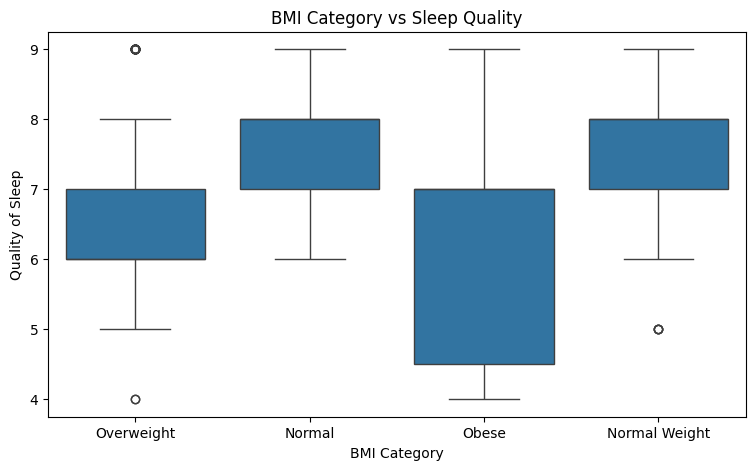

In [25]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="BMI Category",
    y="Quality of Sleep"
)

plt.title("BMI Category vs Sleep Quality")
plt.xlabel("BMI Category")
plt.ylabel("Quality of Sleep")
plt.show()

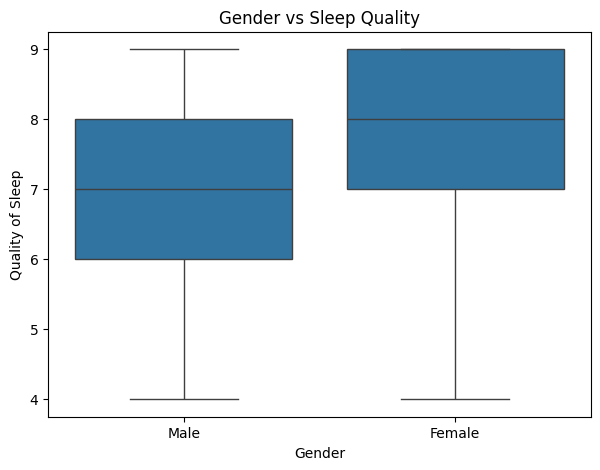

In [26]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Gender",
    y="Quality of Sleep"
)

plt.title("Gender vs Sleep Quality")
plt.xlabel("Gender")
plt.ylabel("Quality of Sleep")
plt.show()

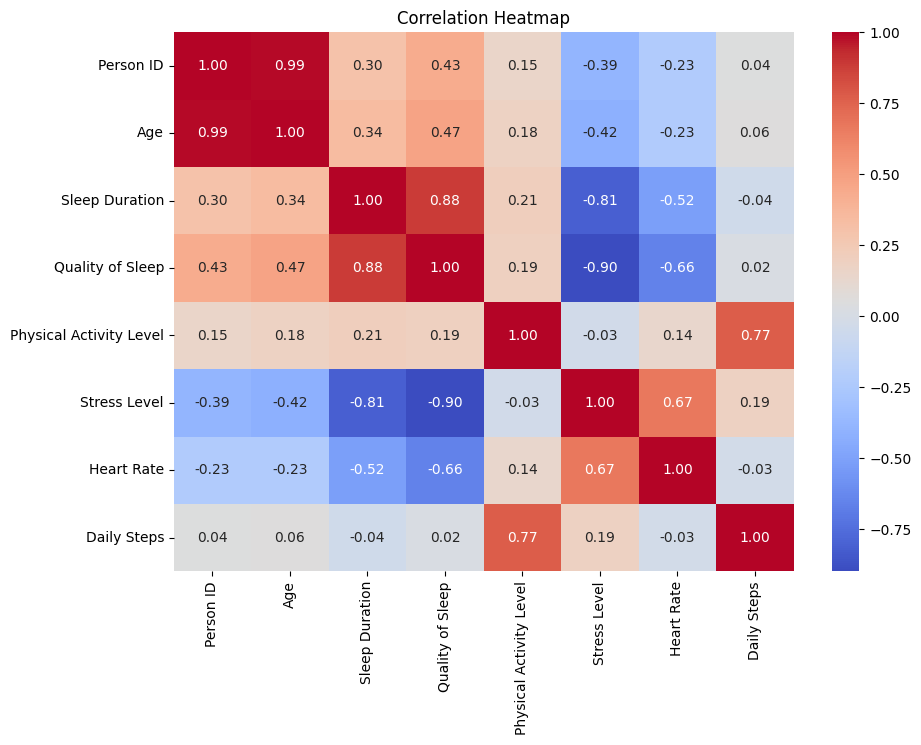

In [27]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [28]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [29]:
print(df["Sleep Disorder"].value_counts(dropna=False))

Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


## 7. Data Cleaning and Preprocessing

### 7.1 Standardising BMI Categories

During data inspection, we identified two categories: `Normal` and `Normal Weight`.

Both represent the same BMI classification. To maintain consistency and avoid treating them as separate categories, we merged `Normal Weight` into `Normal`.

This standardisation helps ensure consistent categorical data during model training.


In [30]:
print(df["BMI Category"].unique())

['Overweight' 'Normal' 'Obese' 'Normal Weight']


In [31]:
df["BMI Category"] = df["BMI Category"].replace({
    "Normal Weight": "Normal"
})

print(df["BMI Category"].value_counts())

BMI Category
Normal        216
Overweight    148
Obese          10
Name: count, dtype: int64


In [32]:
X = df.drop(columns=[
    "Person ID",
    "Quality of Sleep",
    "Sleep Disorder"
])

y = df["Quality of Sleep"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (374, 10)
Target shape: (374,)


In [33]:
print("Numerical Features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(X.select_dtypes(include="object").columns.tolist())

Numerical Features:
['Age', 'Sleep Duration', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']

Categorical Features:
['Gender', 'Occupation', 'BMI Category', 'Blood Pressure']


### 7.2 Splitting Blood Pressure

The original `Blood Pressure` column stores systolic and diastolic pressure together in a format such as `126/83`.

To make this information suitable for Machine Learning:

* We split the original column into two separate columns: `Systolic BP` and `Diastolic BP`.
* Both values are converted into integers.
* The original `Blood Pressure` column is removed after extraction.

This allows the model to treat systolic and diastolic blood pressure as separate numerical features.


In [34]:
print(df["Blood Pressure"].unique()[:15])

['126/83' '125/80' '140/90' '120/80' '132/87' '130/86' '117/76' '118/76'
 '128/85' '131/86' '128/84' '115/75' '135/88' '129/84' '130/85']


In [35]:
df[["Systolic BP", "Diastolic BP"]] = df["Blood Pressure"].str.split("/", expand=True).astype(int)

df = df.drop(columns=["Blood Pressure"])

print(df[["Systolic BP", "Diastolic BP"]].head())

   Systolic BP  Diastolic BP
0          126            83
1          125            80
2          125            80
3          140            90
4          140            90


### 7.3 Feature Selection and Target Variable

Before training the Machine Learning models, we separate the dataset into input features and the target variable.

* **Input features (X):** Contains the selected lifestyle, demographic and health-related attributes used for prediction.
* **Target variable (y):** Contains the `Quality of Sleep` score that the model aims to predict.

The following columns are excluded:

* `Person ID`: It is only an identifier and does not provide meaningful predictive information.
* `Sleep Disorder`: It contains 219 missing values, so it is excluded from the input features.

All remaining selected features are used to train the regression models.


In [36]:
X = df.drop(columns=[
    "Person ID",
    "Quality of Sleep",
    "Sleep Disorder"
])

y = df["Quality of Sleep"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Features shape: (374, 11)
Target shape: (374,)

Features:
['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP']


### 7.4 Splitting the Dataset into Training and Testing Sets

Before training the models, we divide the dataset into training and testing subsets using Scikit-learn's `train_test_split()` function.

We use an 80:20 split:

* **Training set (80%):** Used by the model to learn patterns from the data.
* **Testing set (20%):** Used to evaluate the model on data that was not used during training.

The `random_state=42` parameter ensures that the same split can be reproduced when the code is executed again.

The dataset contains 374 records, resulting in approximately 299 training records and 75 testing records.


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (299, 11)
Testing features: (75, 11)
Training targets: (299,)
Testing targets: (75,)


In [38]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

### 7.5 Feature Transformation and Encoding

Machine Learning models require numerical inputs. However, our dataset contains both numerical and categorical features.

To prepare the data, we use the following techniques:

**1. Numerical Feature Scaling**

We use `StandardScaler()` to standardise numerical features so that they have a mean of approximately 0 and a standard deviation of approximately 1.

**2. Categorical Feature Encoding**

We use `OneHotEncoder()` to convert categorical features such as Gender, Occupation and BMI Category into numerical representations.

**3. ColumnTransformer**

We use `ColumnTransformer` to apply the appropriate preprocessing technique to each feature type.

This preprocessing is included in a Scikit-learn Pipeline so that transformations are fitted on the training data and consistently applied to testing data.


In [39]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Age', 'Sleep Duration', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP']

Categorical features: ['Gender', 'Occupation', 'BMI Category']


In [40]:
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 8. Model Training and Evaluation

### 8.1 Linear Regression

Linear Regression is used as the first model in this project. It is a supervised Machine Learning algorithm used to predict continuous numerical values.

In SleepSense, Linear Regression learns the relationship between the input features and the `Quality of Sleep` score.

**Implementation:**

* We create a Pipeline combining the preprocessing steps and the Linear Regression algorithm.
* The model is trained using `X_train` and `y_train`.
* Predictions are generated using the testing data (`X_test`).

Linear Regression serves as a baseline model against which we can compare the performance of more advanced regression algorithms.


### 8.2 Random Forest Regression

Random Forest Regression is an ensemble Machine Learning algorithm that combines multiple Decision Trees to make predictions.

Instead of relying on a single tree, it combines predictions from several trees to produce a more robust result.

**Implementation:**

* We use `RandomForestRegressor()` with 100 decision trees.
* The model is integrated with the preprocessing steps using a Pipeline.
* It is trained using the training dataset.
* Predictions are generated using the testing dataset.

We compare its performance with Linear Regression to identify which model predicts Quality of Sleep more accurately.


In [41]:
from sklearn.linear_model import LinearRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [42]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [43]:
y_pred = model.predict(X_test)

print("Actual Quality Scores:")
print(y_test.values[:10])

print("\nPredicted Quality Scores:")
print(y_pred[:10])

Actual Quality Scores:
[9 6 6 9 6 6 6 8 9 8]

Predicted Quality Scores:
[9.05504404 5.80439788 5.83195954 9.05504404 5.83163598 6.02784431
 5.88732459 8.11579922 9.08228214 7.90961198]


### 8.3 Model Evaluation Metrics

We evaluate the performance of our regression models using three standard evaluation metrics.

**1. Mean Absolute Error (MAE)**

Measures the average absolute difference between actual and predicted values. Lower MAE indicates better predictions.

**2. Root Mean Squared Error (RMSE)**

Measures prediction errors while giving greater weight to larger errors. Lower RMSE indicates better performance.

**3. R² Score (Coefficient of Determination)**

Measures how well the model explains the variation in the target variable. A value closer to 1 generally indicates a better fit.

These metrics help us compare Linear Regression and Random Forest Regression.


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R² Score:", round(r2, 3))

Model Evaluation Results
------------------------
MAE: 0.116
RMSE: 0.219
R² Score: 0.968


In [45]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [46]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [47]:
rf_pred = rf_model.predict(X_test)

print("Actual Quality Scores:")
print(y_test.values[:10])

print("\nRandom Forest Predictions:")
print(rf_pred[:10])

Actual Quality Scores:
[9 6 6 9 6 6 6 8 9 8]

Random Forest Predictions:
[9. 6. 6. 9. 6. 6. 6. 8. 9. 8.]


In [48]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R² Score:", round(rf_r2, 3))

Random Forest Evaluation Results
--------------------------------
MAE: 0.039
RMSE: 0.129
R² Score: 0.989


### 8.4 Actual vs Predicted Values

We visualise the performance of the Random Forest model by comparing actual Quality of Sleep scores with predicted scores.

A scatter plot is used for this comparison.

* The X-axis represents actual Quality of Sleep values.
* The Y-axis represents predicted Quality of Sleep values.
* A reference diagonal line represents perfect predictions.

Points closer to the diagonal line indicate more accurate predictions.

This visualisation helps us understand how closely the model's predictions match the actual values.


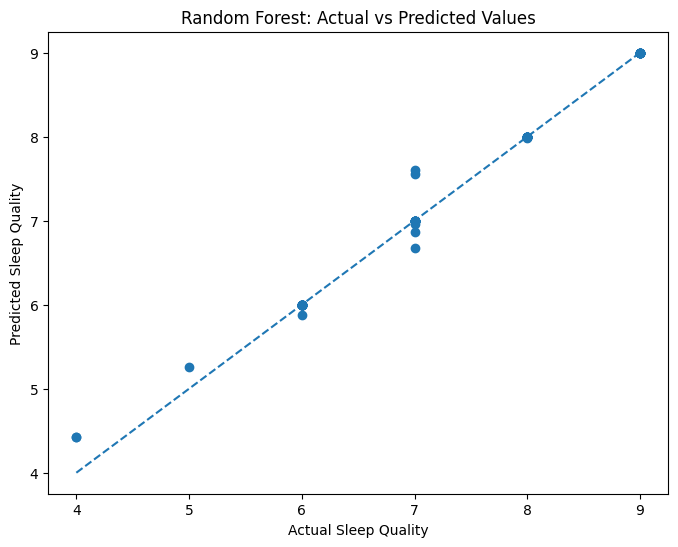

In [49]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sleep Quality")
plt.ylabel("Predicted Sleep Quality")
plt.title("Random Forest: Actual vs Predicted Values")

plt.show()

### 8.5 Feature Importance Analysis

We analyse feature importance to understand which input features contribute most to the Random Forest model's predictions.

The Random Forest algorithm provides feature importance scores that indicate the relative contribution of each feature to the model.

**Key observations:**

* Sleep Duration is the most influential feature, contributing approximately 79.05% of the total feature importance.
* Stress Level is the second most influential feature, contributing approximately 10.61%.
* Other features, such as Occupation and Heart Rate, have comparatively smaller importance scores.

Together, Sleep Duration and Stress Level account for approximately 89.66% of the model's feature importance.

These results describe the model's learned patterns and should not be interpreted as proof of causation.


In [50]:
# Get the trained Random Forest model
rf = rf_model.named_steps["regressor"]

# Get the preprocessing step
preprocessor_fitted = rf_model.named_steps["preprocessor"]

# Get feature names after encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance
importance = rf.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                                 Feature  Importance
1                    num__Sleep Duration    0.790503
3                      num__Stress Level    0.106081
11                cat__Occupation_Doctor    0.036348
4                        num__Heart Rate    0.032426
5                       num__Daily Steps    0.008698
0                               num__Age    0.007710
10            cat__Occupation_Accountant    0.006153
21              cat__BMI Category_Normal    0.003041
2           num__Physical Activity Level    0.001580
7                      num__Diastolic BP    0.001285
6                       num__Systolic BP    0.001285
23          cat__BMI Category_Overweight    0.001151
12              cat__Occupation_Engineer    0.001118
20               cat__Occupation_Teacher    0.000842
18             cat__Occupation_Scientist    0.000591
13                cat__Occupation_Lawyer    0.000498
22               cat__BMI Category_Obese    0.000165
9                       cat__Gender_Male    0.

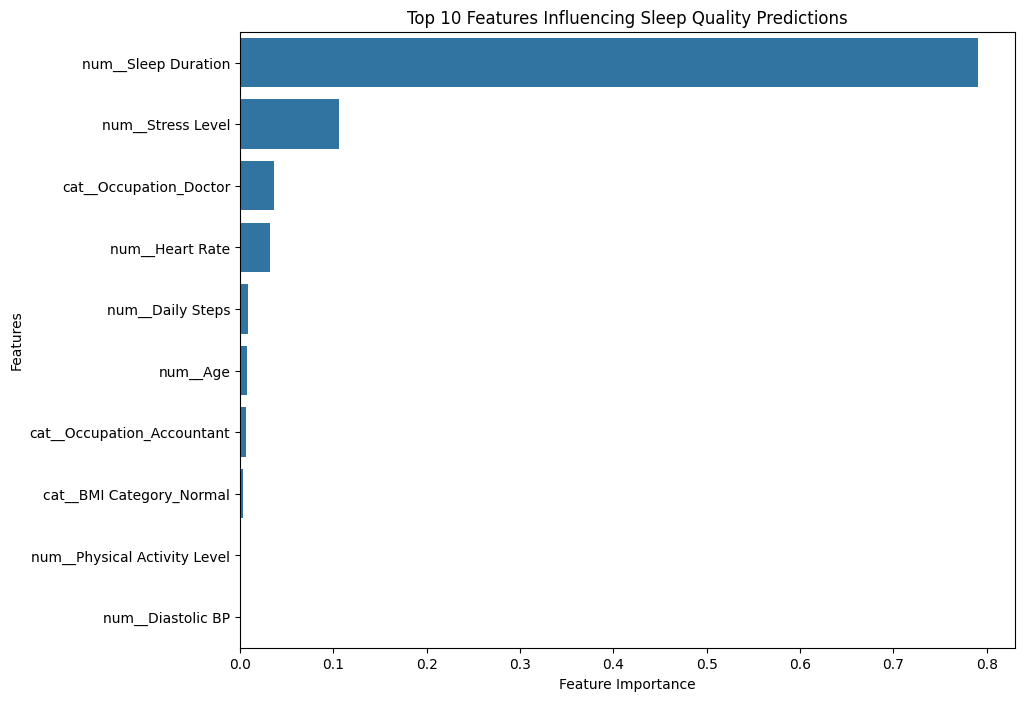

In [51]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Sleep Quality Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()

In [52]:
# Predictions on training data
rf_train_pred = rf_model.predict(X_train)

# Training performance
train_r2 = r2_score(y_train, rf_train_pred)
test_r2 = r2_score(y_test, rf_pred)

print("Random Forest Performance Comparison")
print("------------------------------------")
print("Training R²:", round(train_r2, 3))
print("Testing R²:", round(test_r2, 3))

Random Forest Performance Comparison
------------------------------------
Training R²: 0.997
Testing R²: 0.989


In [53]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:", cv_scores)
print("Average R²:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Cross-validation R² scores: [0.30747885 0.71747718 0.94426851 0.92950329 0.64579057]
Average R²: 0.709
Standard deviation: 0.232


In [54]:
cv_mae = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_mae = -cv_mae

print("Cross-validation MAE scores:", cv_mae)
print("Average MAE:", round(cv_mae.mean(), 3))
print("Standard deviation:", round(cv_mae.std(), 3))

Cross-validation MAE scores: [0.51106667 0.30333333 0.09573333 0.06773333 0.34405405]
Average MAE: 0.264
Standard deviation: 0.165


In [55]:
print("Sleep Quality Distribution:")
print(y.value_counts().sort_index())

Sleep Quality Distribution:
Quality of Sleep
4      5
5      7
6    105
7     77
8    109
9     71
Name: count, dtype: int64


In [56]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold, (_, val_index) in enumerate(kf.split(X), start=1):
    print(f"\nFold {fold}")
    print(y.iloc[val_index].value_counts().sort_index())


Fold 1
Quality of Sleep
4     2
5     1
6    26
7    16
8    18
9    12
Name: count, dtype: int64

Fold 2
Quality of Sleep
4     1
5     5
6    23
7    11
8    19
9    16
Name: count, dtype: int64

Fold 3
Quality of Sleep
6    21
7    15
8    27
9    12
Name: count, dtype: int64

Fold 4
Quality of Sleep
4     1
6    18
7    16
8    26
9    14
Name: count, dtype: int64

Fold 5
Quality of Sleep
4     1
5     1
6    17
7    19
8    19
9    17
Name: count, dtype: int64


In [57]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

stratified_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=skf.split(X, y),
    scoring="r2"
)

print("Stratified CV R² scores:", stratified_scores)
print("Average R²:", round(stratified_scores.mean(), 3))
print("Standard deviation:", round(stratified_scores.std(), 3))

Stratified CV R² scores: [0.97185775 0.99348831 0.95799416 0.99496903 0.98689935]
Average R²: 0.981
Standard deviation: 0.014


In [58]:
stratified_mae = cross_val_score(
    rf_model,
    X,
    y,
    cv=skf.split(X, y),
    scoring="neg_mean_absolute_error"
)

stratified_mae = -stratified_mae

print("Stratified CV MAE scores:", stratified_mae)
print("Average MAE:", round(stratified_mae.mean(), 3))
print("Standard deviation:", round(stratified_mae.std(), 3))

Stratified CV MAE scores: [0.0536     0.02466667 0.0752     0.02186667 0.04743243]
Average MAE: 0.045
Standard deviation: 0.02


In [59]:
print("Duplicate feature combinations:", X.duplicated().sum())

print("\nDuplicate feature combinations with target:")
print(
    pd.concat([X, y], axis=1)
    .duplicated()
    .sum()
)

Duplicate feature combinations: 265

Duplicate feature combinations with target:
265


In [60]:
print("Total records:", len(X))
print("Unique feature combinations:", len(X.drop_duplicates()))

print(
    "Percentage of repeated records:",
    round((X.duplicated().sum() / len(X)) * 100, 2),
    "%"
)

Total records: 374
Unique feature combinations: 109
Percentage of repeated records: 70.86 %


## 9. Model Validation

### 9.1 Group K-Fold Cross-Validation

A single train-test split may not provide a complete picture of a model's performance. Therefore, we use Group K-Fold Cross-Validation for additional evaluation.

The dataset contains repeated feature combinations. To avoid placing identical feature combinations in both training and validation sets, we use Group K-Fold.

The dataset is divided into five groups:

* In each iteration, four groups are used for training.
* The remaining group is used for validation.
* This process is repeated until every group has been used for validation.

This approach provides a more reliable assessment of how the model performs on previously unseen feature combinations.


### 9.2 Random Forest Cross-Validation Results

We evaluate the Random Forest model using 5-fold Group K-Fold Cross-Validation.

The evaluation produces the following average results:

| Evaluation Metric | Mean Score |
| ----------------- | ---------: |
| R² Score          |      0.958 |
| MAE               |      0.076 |
| RMSE              |      0.236 |

The R² score of 0.958 indicates that the model explains a large proportion of the variation in Quality of Sleep across the validation folds.

The relatively low MAE indicates that the average absolute prediction error is small.

These results are based on this particular dataset and validation strategy. They do not guarantee similar performance on completely new real-world data.


In [61]:
from sklearn.model_selection import GroupKFold, cross_val_score

# Give identical feature combinations the same group ID
groups = pd.util.hash_pandas_object(X, index=False)

gkf = GroupKFold(n_splits=5)

group_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=gkf,
    groups=groups,
    scoring="r2"
)

print("Group CV R² scores:", group_scores)
print("Average R²:", round(group_scores.mean(), 3))
print("Standard deviation:", round(group_scores.std(), 3))

Group CV R² scores: [0.95536125 0.92679783 0.96845614 0.95777926 0.98004165]
Average R²: 0.958
Standard deviation: 0.018


In [62]:
group_mae = cross_val_score(
    rf_model,
    X,
    y,
    cv=gkf,
    groups=groups,
    scoring="neg_mean_absolute_error"
)

group_mae = -group_mae

print("Group CV MAE scores:", group_mae)
print("Average MAE:", round(group_mae.mean(), 3))
print("Standard deviation:", round(group_mae.std(), 3))

Group CV MAE scores: [0.07306667 0.11466667 0.07813333 0.08186667 0.03135135]
Average MAE: 0.076
Standard deviation: 0.027


### 9.4 Feature Ablation Analysis

To understand the importance of Sleep Duration and Stress Level, we performed an additional experiment by removing both features and training the Random Forest model again.

**Results:**

| Model Configuration                     | Mean Group K-Fold R² |
| --------------------------------------- | -------------------: |
| All features included                   |                0.958 |
| Sleep Duration and Stress Level removed |                0.798 |

**Observations:**

* Removing these two features reduced the R² score from 0.958 to 0.798.
* The model still retained predictive information from the remaining features.
* This experiment highlights the importance of Sleep Duration and Stress Level in the model's predictions.

This is a feature ablation experiment. It helps us understand the model's dependence on particular inputs but does not establish causal relationships.


In [63]:
# Remove the two most important features
X_reduced = X.drop(columns=["Sleep Duration", "Stress Level"])

# Keep identical feature combinations in the same fold
reduced_groups = pd.util.hash_pandas_object(X_reduced, index=False)

# Create a new preprocessing pipeline
reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(),
         X_reduced.select_dtypes(include=np.number).columns.tolist()),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         X_reduced.select_dtypes(include="object").columns.tolist())
    ]
)

reduced_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

reduced_scores = cross_val_score(
    reduced_model,
    X_reduced,
    y,
    cv=gkf,
    groups=reduced_groups,
    scoring="r2"
)

print("R² without Sleep Duration and Stress Level:", reduced_scores)
print("Average R²:", round(reduced_scores.mean(), 3))

R² without Sleep Duration and Stress Level: [0.90013196 0.65877316 0.72222583 0.8122843  0.8973952 ]
Average R²: 0.798


### 9.3 Comparison of Regression Models

We compare Linear Regression and Random Forest Regression using the same Group K-Fold validation strategy.

| Model             | Mean R² Score | Mean MAE |
| ----------------- | ------------: | -------: |
| Linear Regression |         0.927 |    0.179 |
| Random Forest     |         0.958 |    0.076 |

**Observations:**

* Random Forest achieves a higher average R² score.
* Random Forest also has a lower MAE, indicating smaller average prediction errors.
* Both models perform well, but Random Forest performs better on this dataset under the selected validation strategy.

Therefore, Random Forest is selected as the better-performing model for SleepSense.


In [64]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=gkf,
    groups=groups,
    scoring="r2"
)

linear_mae = cross_val_score(
    linear_model,
    X,
    y,
    cv=gkf,
    groups=groups,
    scoring="neg_mean_absolute_error"
)

linear_mae = -linear_mae

print("Linear Regression Group CV R²:", linear_scores)
print("Average R²:", round(linear_scores.mean(), 3))

print("\nLinear Regression Group CV MAE:", linear_mae)
print("Average MAE:", round(linear_mae.mean(), 3))

Linear Regression Group CV R²: [0.8942257  0.92193476 0.94180419 0.93777996 0.93763398]
Average R²: 0.927

Linear Regression Group CV MAE: [0.20356938 0.21409076 0.1648282  0.14617214 0.16793661]
Average MAE: 0.179


In [65]:
group_mse = cross_val_score(
    rf_model,
    X,
    y,
    cv=gkf,
    groups=groups,
    scoring="neg_mean_squared_error"
)

group_rmse = np.sqrt(-group_mse)

print("Group CV RMSE scores:", group_rmse)
print("Average RMSE:", round(group_rmse.mean(), 3))

Group CV RMSE scores: [0.21013012 0.36958355 0.21721878 0.21872967 0.16555394]
Average RMSE: 0.236


In [66]:
df[[
    "Person ID",
    "Age",
    "Sleep Duration",
    "Stress Level",
    "Quality of Sleep"
]].head(20)

,Person ID,Age,Sleep Duration,Stress Level,Quality of Sleep
0,1,27,6.1,6,6
1,2,28,6.2,8,6
2,3,28,6.2,8,6
3,4,28,5.9,8,4
4,5,28,5.9,8,4
5,6,28,5.9,8,4
6,7,29,6.3,7,6
7,8,29,7.8,6,7
8,9,29,7.8,6,7
9,10,29,7.8,6,7


In [67]:
print(
    "Consecutive identical feature records:",
    X.eq(X.shift()).all(axis=1).sum()
)

Consecutive identical feature records: 165


In [68]:
print("Consecutive identical full records:",
      df.eq(df.shift()).all(axis=1).sum())

print("Total exact duplicate full records:",
      df.duplicated().sum())

Consecutive identical full records: 0
Total exact duplicate full records: 0


In [69]:
print(
    df.groupby(
        ["Sleep Duration", "Stress Level"]
    )["Quality of Sleep"].nunique().value_counts().sort_index()
)

Quality of Sleep
1    44
2     6
3     1
Name: count, dtype: int64


In [70]:
combination_counts = (
    df.groupby(["Sleep Duration", "Stress Level"])["Quality of Sleep"]
    .nunique()
)

ambiguous = combination_counts[combination_counts > 1].index

print(
    df.set_index(["Sleep Duration", "Stress Level"])
      .loc[ambiguous]
      .sort_index()
)

                             Person ID  Gender  Age            Occupation  \
Sleep Duration Stress Level                                                 
5.9            8                     4    Male   28  Sales Representative   
               8                     5    Male   28  Sales Representative   
               8                     6    Male   28     Software Engineer   
               8                   266  Female   48                 Nurse   
6.4            7                    31  Female   30                 Nurse   
               7                    32  Female   30                 Nurse   
               7                   192    Male   43           Salesperson   
               7                   222    Male   44           Salesperson   
               7                   224    Male   44           Salesperson   
               7                   237    Male   44           Salesperson   
               7                   240    Male   44           Salesperson   

In [71]:
check = pd.concat([X, y], axis=1)

consistency = check.groupby(
    list(X.columns)
)["Quality of Sleep"].nunique()

print("Feature combinations:", len(consistency))
print("Combinations with conflicting targets:", (consistency > 1).sum())

Feature combinations: 109
Combinations with conflicting targets: 0


## 10. Conclusion

SleepSense demonstrates how machine learning can be used to predict sleep quality from lifestyle and health-related attributes.

We implemented and compared Linear Regression and Random Forest Regression. Based on Group K-Fold cross-validation, Random Forest achieved better performance, with a mean R² score of 0.958 and mean MAE of 0.076.

The feature analysis showed that Sleep Duration and Stress Level were particularly influential in the model's predictions.

### Key Learnings

* Data cleaning and preprocessing are essential before model training.
* Different regression algorithms can produce different prediction results.
* Cross-validation provides a more reliable evaluation than relying on a single train-test split.
* Feature importance and ablation analysis help us understand model behaviour.

### Limitations

* The dataset contains only 374 records.
* Repeated feature combinations may affect how well the model generalises to new individuals.
* The dataset's collection methodology is not fully established.
* The model predicts patterns in the dataset and does not establish medical or causal relationships.

### Future Scope

* Evaluate the model on a larger and more diverse dataset.
* Test its performance on genuinely new, unseen individuals.
* Develop a simple user interface to make predictions easier to access.
* Explore additional features that may improve prediction reliability.

**Note:** SleepSense is an educational machine learning project, not a medical diagnostic tool.
